# Resultados Fase 2: Generación de Reportes Clínicos

Análisis multi-dataset de la generación de reportes por LLaVA-Med y Mini-VLM:

| Dataset | gt_label | reference | Métricas disponibles |
|---------|----------|-----------|---------------------|
| HAM10000 | ✅ | ❌ | Clasificación + NER |
| SkinCaRe | ✅ | ✅ (resumen CoT) | Clasificación + NER + Similitud textual |
| MM-SkinQA | ❌ | ✅ (histopatología) | Similitud textual + NER entity recall |

**Estructura del notebook:**
1. Setup y carga de reportes
2. HAM10000: clasificación + NER
3. SkinCaRe: NER + similitud textual
4. MM-SkinQA: similitud textual
5. Comparación global de similitud textual

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

REPO_ROOT = Path("..").resolve()
sys.path.insert(0, str(REPO_ROOT))

RESULTS_DIR = REPO_ROOT / "outputs" / "results"
REPORTS_DIR = REPO_ROOT / "outputs" / "generated_reports"
CACHE_DIR = REPO_ROOT / "outputs" / "metrics_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["llava_med", "mini_vlm"]
DATASETS = ["HAM10000", "skincare", "mmskin"]
MODEL_LABELS = {"llava_med": "LLaVA-Med", "mini_vlm": "Mini-VLM"}

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (12, 5)

HAM_CLASSES = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]


def load_json(path: Path) -> dict | None:
    """Carga un JSON, devuelve None si no existe."""
    if not path.exists():
        print(f"[WARN] No encontrado: {path.relative_to(REPO_ROOT)}")
        return None
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def load_reports(model: str, dataset: str) -> pd.DataFrame:
    """Carga todos los reportes JSON de un modelo/dataset en un DataFrame."""
    report_dir = REPORTS_DIR / model / dataset
    if not report_dir.exists():
        print(f"[WARN] Directorio no encontrado: {report_dir.relative_to(REPO_ROOT)}")
        return pd.DataFrame()
    records = []
    for p in sorted(report_dir.glob("*_report.json")):
        try:
            with open(p, encoding="utf-8") as f:
                records.append(json.load(f))
        except (json.JSONDecodeError, OSError):
            pass
    return pd.DataFrame(records)


# Cargar todos los reportes
reports: dict[str, dict[str, pd.DataFrame]] = {}
for model in MODELS:
    reports[model] = {}
    for dataset in DATASETS:
        df = load_reports(model, dataset)
        reports[model][dataset] = df
        if not df.empty:
            has_label = (df["gt_label"].astype(str).str.strip() != "").sum() if "gt_label" in df.columns else 0
            has_ref = (df["reference"].astype(str).str.strip() != "").sum() if "reference" in df.columns else 0
            print(f"{MODEL_LABELS[model]} / {dataset}: {len(df)} reportes | "
                  f"gt_label={has_label} | reference={has_ref}")

LLaVA-Med / HAM10000: 3042 reportes | gt_label=3042 | reference=0
LLaVA-Med / skincare: 3023 reportes | gt_label=3023 | reference=2814
LLaVA-Med / mmskin: 20 reportes | gt_label=0 | reference=20
Mini-VLM / HAM10000: 2240 reportes | gt_label=2240 | reference=0
Mini-VLM / skincare: 3023 reportes | gt_label=3023 | reference=2814
Mini-VLM / mmskin: 2809 reportes | gt_label=0 | reference=2809


---
## 1. HAM10000

Análisis de clasificación (cargado desde resultados pre-computados) y calidad de reportes vía NER clínico.

In [2]:
# --- 1a. Tabla comparativa de clasificación ---
from src.evaluation.report_builder import build_comparison_table

cls_files = {
    "DenseNet-121": "densenet_test_results.json",
    "ViT-B/16": "vit_test_results.json",
    "LLaVA-Med (zero-shot)": "llava_med_test_results.json",
    "LLaVA-Med (fine-tuned)": "llava_med_finetuned_test_results.json",
    "Mini-VLM (zero-shot)": "mini_vlm_test_results.json",
    "Mini-VLM (fine-tuned)": "mini_vlm_finetuned_test_results.json",
}

cls_data = {name: load_json(RESULTS_DIR / fname) for name, fname in cls_files.items()}
cls_data = {k: v for k, v in cls_data.items() if v is not None}

if cls_data:
    metrics_cols = ["accuracy", "f1_weighted", "sensitivity_macro", "specificity_macro"]
    results_dict = {
        name: {m: data.get(m) for m in metrics_cols}
        for name, data in cls_data.items()
    }
    df_cls = build_comparison_table(results_dict, metrics_cols)
    df_display = df_cls.copy()
    for col in metrics_cols:
        df_display[col] = df_display[col].map(lambda x: f"{x:.4f}" if x is not None else "-")
    df_display.columns = ["Modelo", "Accuracy", "F1 (weighted)", "Sensibilidad (macro)", "Especificidad (macro)"]
    display(df_display.style.set_caption("Tabla 1: Clasificación sobre HAM10000 test set"))
else:
    print("[INFO] No hay resultados de clasificación disponibles.")

[WARN] No encontrado: outputs\results\densenet_test_results.json
[WARN] No encontrado: outputs\results\vit_test_results.json


,Modelo,Accuracy,F1 (weighted),Sensibilidad (macro),Especificidad (macro)
0,LLaVA-Med (zero-shot),0.1144,0.0296,0.1561,0.8580
1,LLaVA-Med (fine-tuned),0.1111,0.0222,0.1429,0.8571
2,Mini-VLM (zero-shot),0.0512,0.0061,0.1439,0.8571
3,Mini-VLM (fine-tuned),0.1118,0.0236,0.1447,0.8573


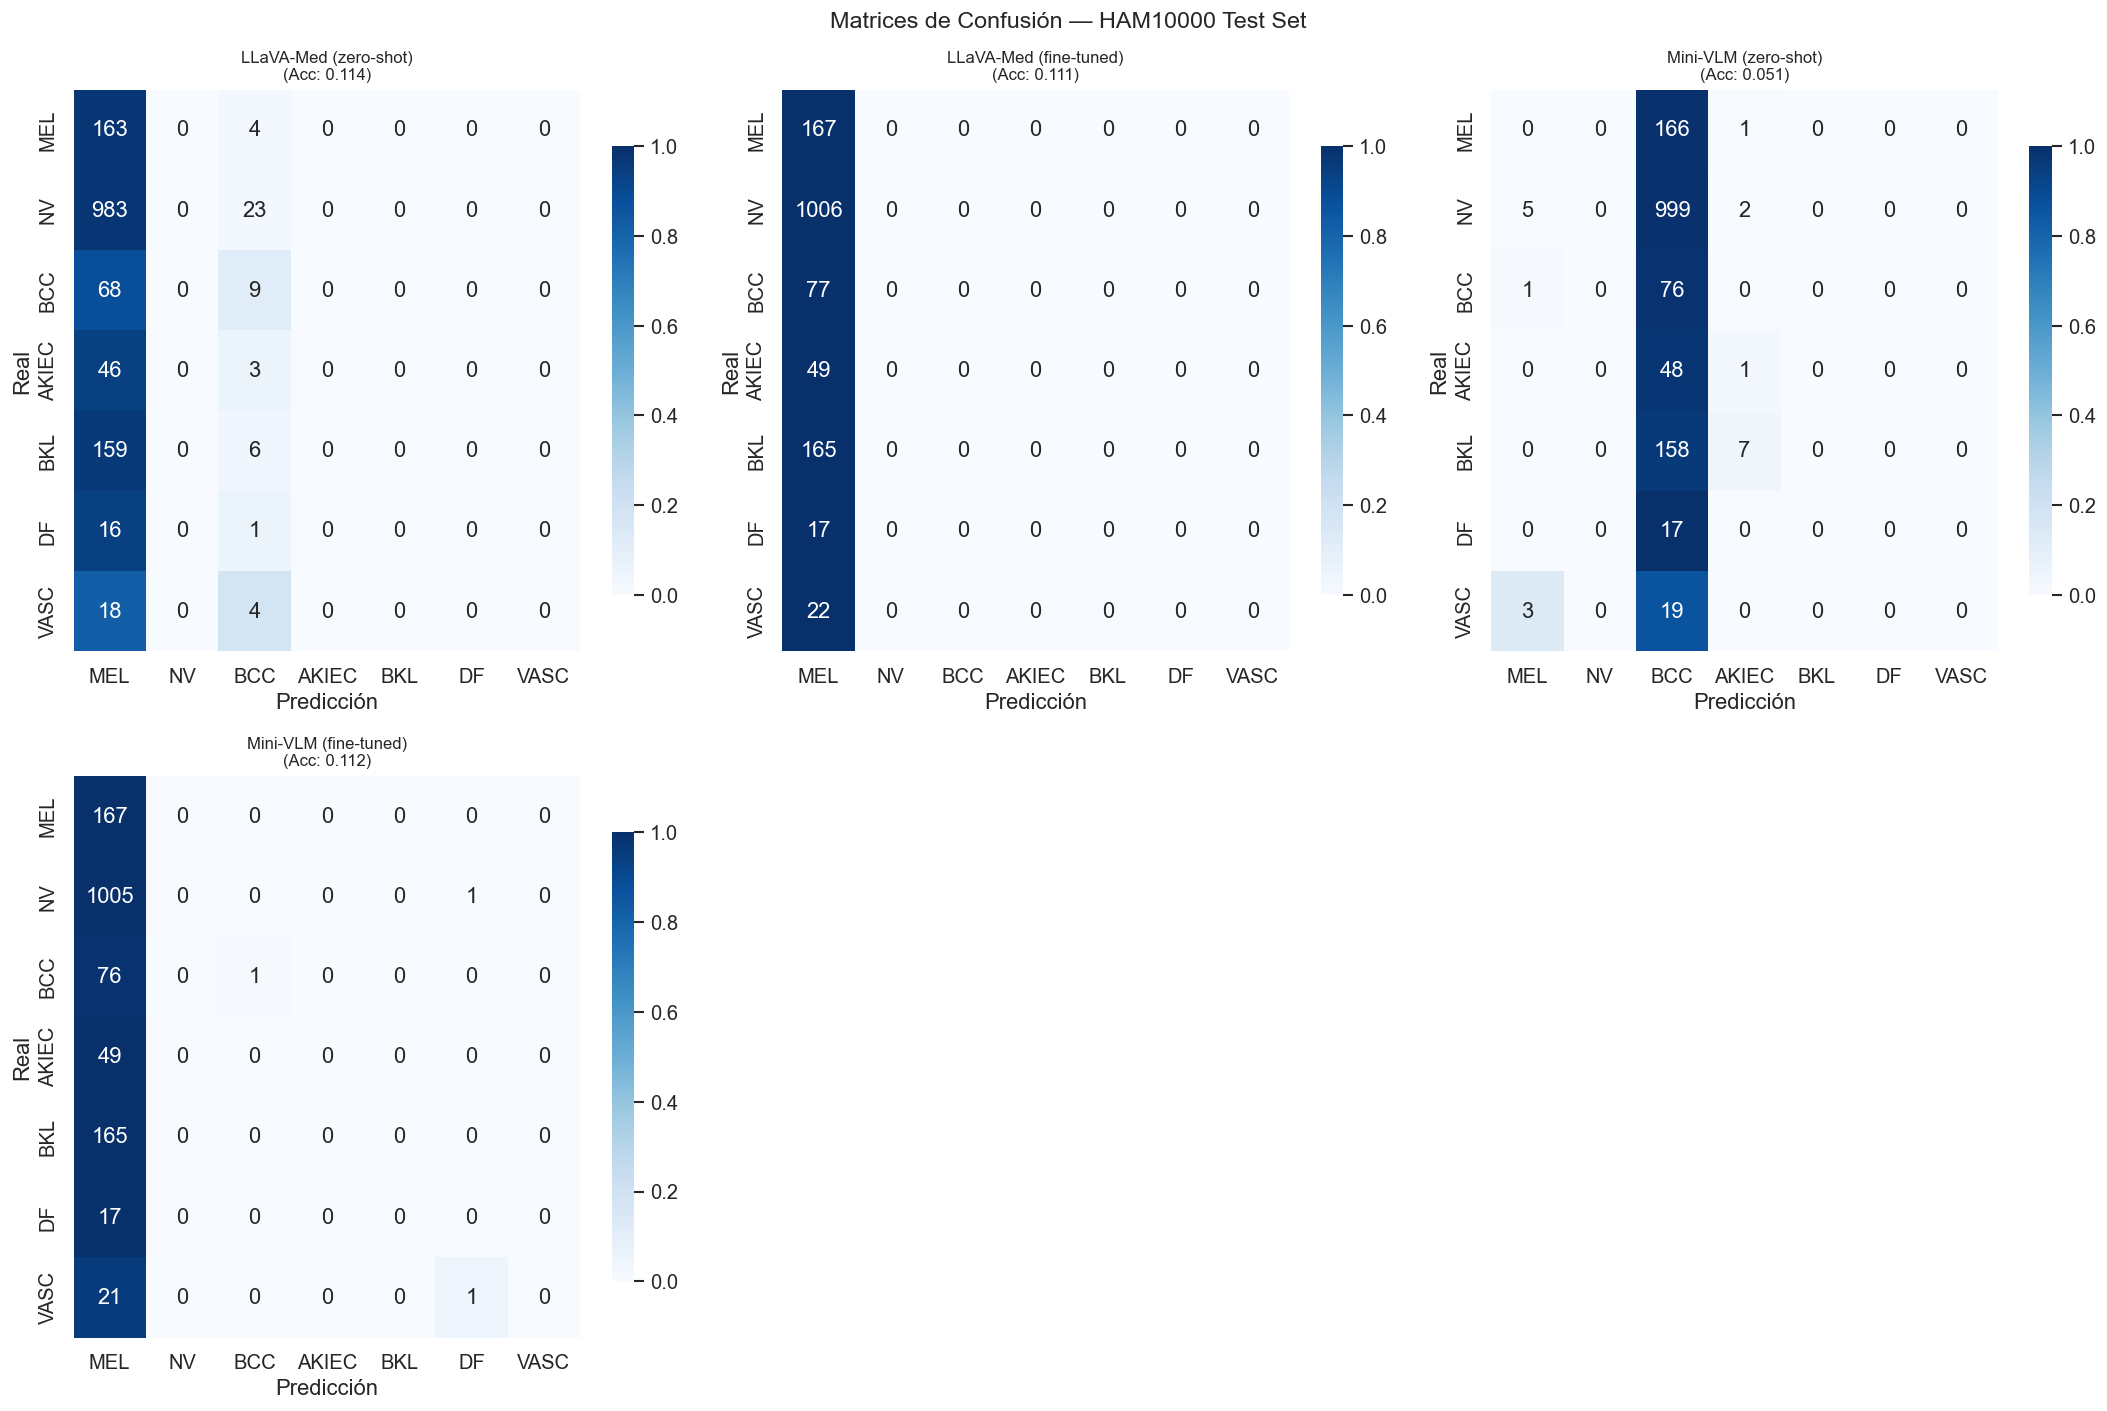

In [3]:
# --- 1b. Matrices de confusión ---
if cls_data:
    n = len(cls_data)
    cols = 3
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(18, 6 * rows))
    axes_flat = np.array(axes).flatten()

    for i, (name, data) in enumerate(cls_data.items()):
        ax = axes_flat[i]
        cm = np.array(data.get("confusion_matrix", []))
        if cm.size == 0:
            ax.set_visible(False)
            continue
        cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        sns.heatmap(
            cm_norm, annot=cm, fmt="d", cmap="Blues",
            xticklabels=HAM_CLASSES, yticklabels=HAM_CLASSES,
            ax=ax, vmin=0, vmax=1, cbar_kws={"shrink": 0.8},
        )
        ax.set_title(f"{name}\n(Acc: {data.get('accuracy', 0):.3f})", fontsize=10)
        ax.set_ylabel("Real")
        ax.set_xlabel("Predicción")

    for j in range(i + 1, len(axes_flat)):
        axes_flat[j].set_visible(False)

    fig.suptitle("Matrices de Confusión — HAM10000 Test Set", fontsize=14)
    plt.tight_layout()
    plt.show()

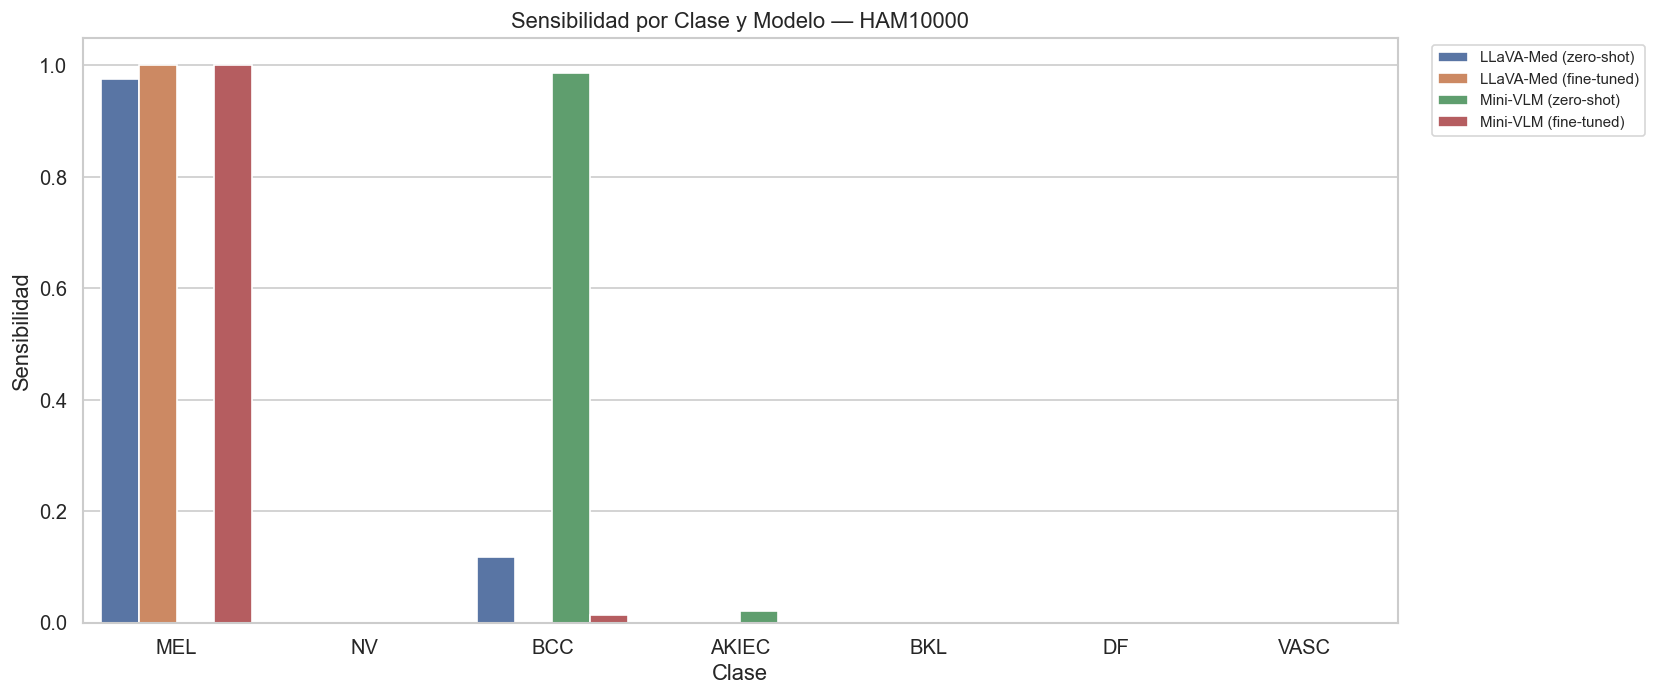

In [4]:
# --- 1c. Sensibilidad por clase ---
if cls_data:
    sens_data = [
        {"Modelo": name, "Clase": cls_name, "Sensibilidad": data["sensitivity_per_class"][cls_idx]}
        for name, data in cls_data.items()
        if data.get("sensitivity_per_class")
        for cls_idx, cls_name in enumerate(HAM_CLASSES)
    ]
    if sens_data:
        df_sens = pd.DataFrame(sens_data)
        fig, ax = plt.subplots(figsize=(14, 6))
        sns.barplot(data=df_sens, x="Clase", y="Sensibilidad", hue="Modelo", ax=ax)
        ax.set_title("Sensibilidad por Clase y Modelo — HAM10000")
        ax.set_ylim(0, 1.05)
        ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
        plt.tight_layout()
        plt.show()

NER HAM10000 cargado desde caché.


,Modelo,Clinical Entity Recall,Diagnostic Consistency,N reportes
0,LLaVA-Med,0.4569,0.7147,3042
1,Mini-VLM,0.6068,0.3134,2240


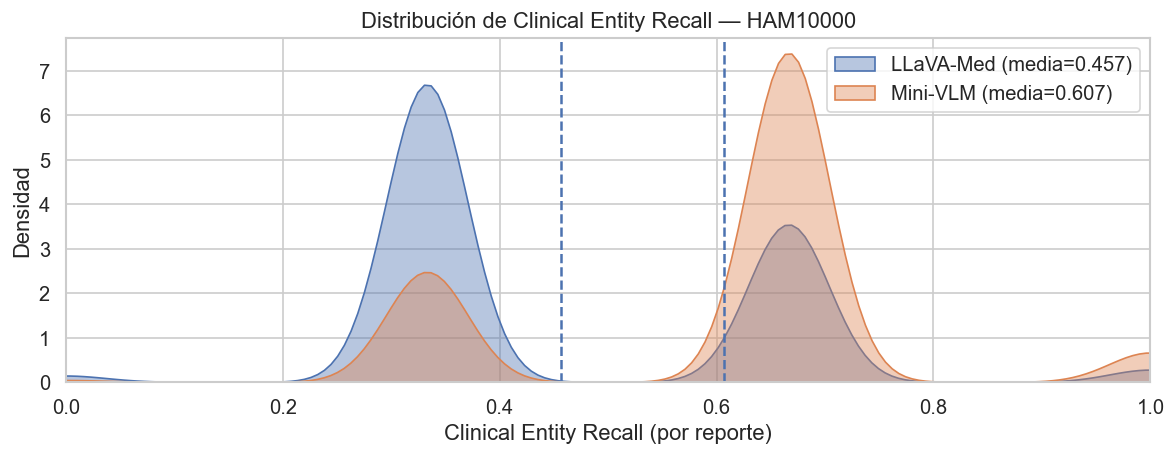

In [5]:
# --- 1d. NER clínico sobre reportes HAM10000 ---
from src.evaluation.clinical_ner import evaluate_clinical_entities

ner_cache_path = CACHE_DIR / "ner_ham10000.json"

if ner_cache_path.exists():
    ner_ham = load_json(ner_cache_path)
    print("NER HAM10000 cargado desde caché.")
else:
    ner_ham = {}
    for model in MODELS:
        df = reports[model]["HAM10000"]
        if df.empty:
            continue
        preds = df["report"].fillna("").tolist()
        labels = df["gt_label"].fillna("").tolist() if "gt_label" in df.columns else None
        has_labels = labels and any(l.strip() for l in labels)
        result = evaluate_clinical_entities(preds, labels if has_labels else None)
        ner_ham[model] = {
            "clinical_entity_recall": result["clinical_entity_recall"],
            "diagnostic_consistency": result.get("diagnostic_consistency"),
            "per_report_recall": [r["recall"] for r in result["per_report"]],
            "n": len(preds),
        }
        print(f"{MODEL_LABELS[model]} HAM10000: entity_recall={result['clinical_entity_recall']:.4f}")
    with open(ner_cache_path, "w", encoding="utf-8") as f:
        json.dump(ner_ham, f, indent=2)

if ner_ham:
    rows_ner = []
    for model, res in ner_ham.items():
        rows_ner.append({
            "Modelo": MODEL_LABELS[model],
            "Clinical Entity Recall": f"{res['clinical_entity_recall']:.4f}",
            "Diagnostic Consistency": f"{res['diagnostic_consistency']:.4f}" if res.get('diagnostic_consistency') is not None else "-",
            "N reportes": res["n"],
        })
    display(pd.DataFrame(rows_ner).style.set_caption("Tabla 2: NER clínico — HAM10000"))

    # Distribución de recall por reporte
    fig, ax = plt.subplots(figsize=(10, 4))
    for model, res in ner_ham.items():
        recalls = res["per_report_recall"]
        mean_r = res["clinical_entity_recall"]
        label = MODEL_LABELS[model]
        sns.kdeplot(recalls, fill=True, alpha=0.4, label=f"{label} (media={mean_r:.3f})", ax=ax)
        ax.axvline(mean_r, linestyle="--", linewidth=1.5)
    ax.set_xlabel("Clinical Entity Recall (por reporte)")
    ax.set_ylabel("Densidad")
    ax.set_title("Distribución de Clinical Entity Recall — HAM10000")
    ax.set_xlim(0, 1)
    ax.legend()
    plt.tight_layout()
    plt.show()

---
## 2. SkinCaRe

Análisis de reportes generados sobre SkinCaRe. Métricas disponibles:
- **NER clínico** (entity recall + diagnostic consistency con gt_label)
- **Similitud textual** (BLEU-4, ROUGE-L, BERTScore) contra el resumen del CoT de referencia

In [6]:
# --- 2a. NER clínico sobre reportes SkinCaRe ---
ner_cache_path_skin = CACHE_DIR / "ner_skincare.json"

if ner_cache_path_skin.exists():
    ner_skin = load_json(ner_cache_path_skin)
    print("NER SkinCaRe cargado desde caché.")
else:
    ner_skin = {}
    for model in MODELS:
        df = reports[model]["skincare"]
        if df.empty:
            continue
        preds = df["report"].fillna("").tolist()
        labels = df["gt_label"].fillna("").tolist() if "gt_label" in df.columns else None
        has_labels = labels and any(l.strip() for l in labels)
        result = evaluate_clinical_entities(preds, labels if has_labels else None)
        ner_skin[model] = {
            "clinical_entity_recall": result["clinical_entity_recall"],
            "diagnostic_consistency": result.get("diagnostic_consistency"),
            "per_report_recall": [r["recall"] for r in result["per_report"]],
            "n": len(preds),
        }
        print(f"{MODEL_LABELS[model]} SkinCaRe: entity_recall={result['clinical_entity_recall']:.4f}")
    with open(ner_cache_path_skin, "w", encoding="utf-8") as f:
        json.dump(ner_skin, f, indent=2)

if ner_skin:
    rows_ner_skin = []
    for model, res in ner_skin.items():
        rows_ner_skin.append({
            "Modelo": MODEL_LABELS[model],
            "Clinical Entity Recall": f"{res['clinical_entity_recall']:.4f}",
            "Diagnostic Consistency": f"{res['diagnostic_consistency']:.4f}" if res.get('diagnostic_consistency') is not None else "-",
            "N reportes": res["n"],
        })
    display(pd.DataFrame(rows_ner_skin).style.set_caption("Tabla 3: NER clínico — SkinCaRe"))

NER SkinCaRe cargado desde caché.


,Modelo,Clinical Entity Recall,Diagnostic Consistency,N reportes
0,LLaVA-Med,0.3709,0.0000,3023
1,Mini-VLM,0.5661,0.0003,3023


In [7]:
# --- 2b. Similitud textual SkinCaRe (BLEU-4, ROUGE-L, BERTScore) ---
from src.evaluation.generation import evaluate_generation

gen_cache_path_skin = CACHE_DIR / "generation_skincare.json"

if gen_cache_path_skin.exists():
    gen_skin = load_json(gen_cache_path_skin)
    print("Métricas de generación SkinCaRe cargadas desde caché.")
else:
    gen_skin = {}
    for model in MODELS:
        df = reports[model]["skincare"]
        if df.empty:
            continue
        # Solo usar filas con referencia no vacía
        mask = df["reference"].fillna("").str.strip().astype(bool) if "reference" in df.columns else pd.Series(False, index=df.index)
        df_with_ref = df[mask]
        if df_with_ref.empty:
            print(f"[WARN] {MODEL_LABELS[model]} SkinCaRe: ningún reporte con referencia.")
            continue
        preds = df_with_ref["report"].fillna("").tolist()
        refs = df_with_ref["reference"].fillna("").tolist()
        print(f"{MODEL_LABELS[model]} SkinCaRe: calculando métricas sobre {len(preds)} pares...")
        result = evaluate_generation(preds, refs, metrics=["bleu_4", "rouge_l", "bertscore_f1"])
        result["n"] = len(preds)
        gen_skin[model] = result
    with open(gen_cache_path_skin, "w", encoding="utf-8") as f:
        json.dump(gen_skin, f, indent=2)

if gen_skin:
    rows_gen_skin = []
    for model, res in gen_skin.items():
        rows_gen_skin.append({
            "Modelo": MODEL_LABELS[model],
            "BLEU-4": f"{res.get('bleu_4', 0):.4f}" if res.get('bleu_4') is not None else "-",
            "ROUGE-L": f"{res.get('rouge_l', 0):.4f}" if res.get('rouge_l') is not None else "-",
            "BERTScore F1": f"{res.get('bertscore_f1', 0):.4f}" if res.get('bertscore_f1') is not None else "-",
            "N pares": res.get("n", "-"),
        })
    display(pd.DataFrame(rows_gen_skin).style.set_caption("Tabla 4: Similitud textual — SkinCaRe vs resumen CoT"))

LLaVA-Med SkinCaRe: calculando métricas sobre 2814 pares...


config.json:   0%|          | 0.00/792 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/3.04G [00:00<?, ?B/s]

... (12 outputs left out)

DebertaModel LOAD REPORT from: microsoft/deberta-xlarge-mnli
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.weight   | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 
pooler.dense.bias   | UNEXPECTED |  | 
classifier.bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,Modelo,BLEU-4,ROUGE-L,BERTScore F1,N pares
0,LLaVA-Med,0.0155,0.0660,0.7054,2814
1,Mini-VLM,0.0347,0.1366,0.7663,2814


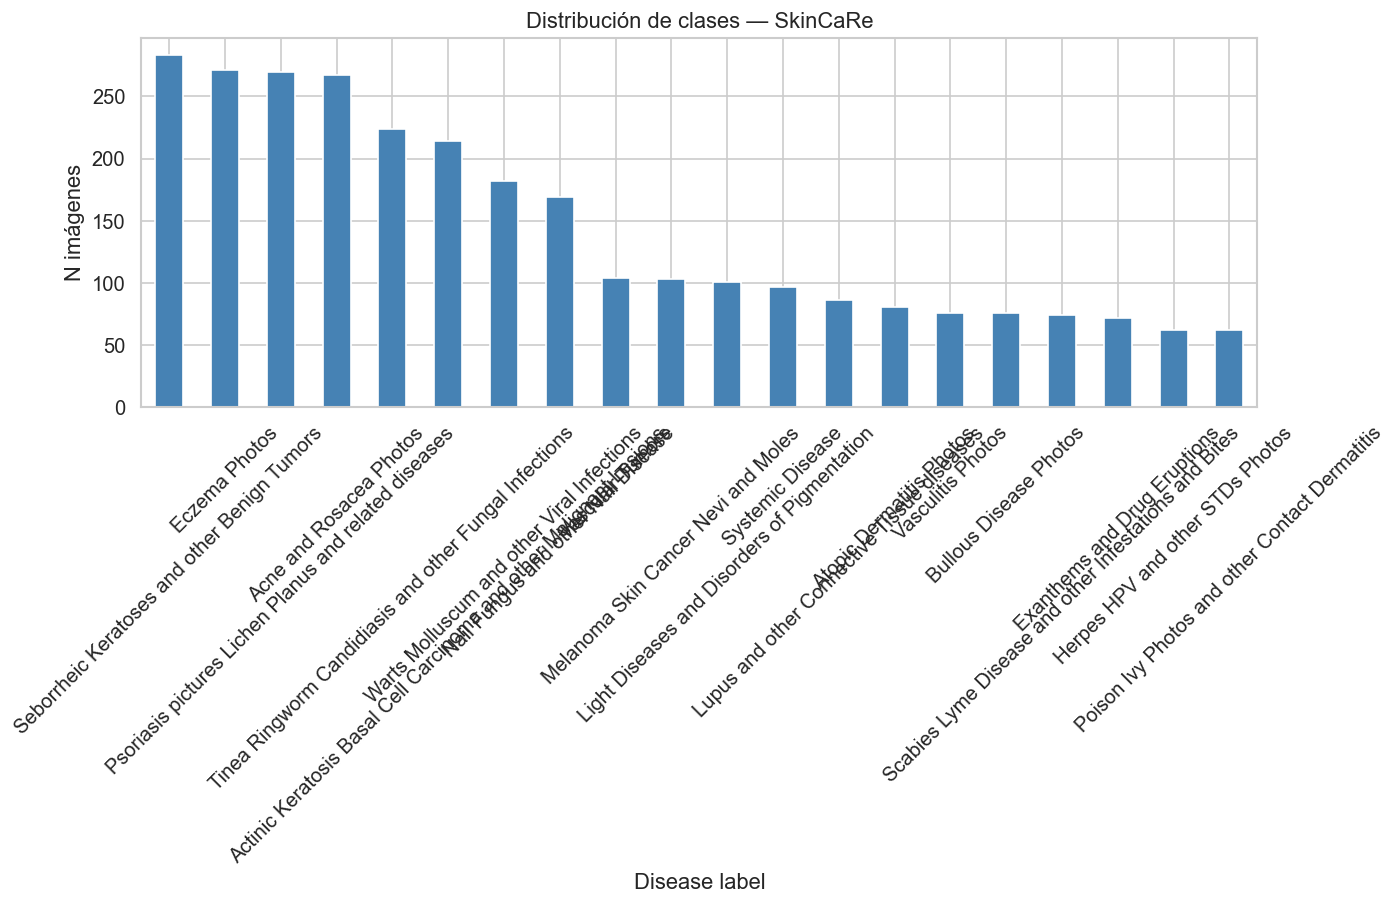

In [8]:
# --- 2c. Distribución de gt_label en SkinCaRe ---
skin_dfs = {model: reports[model]["skincare"] for model in MODELS if not reports[model]["skincare"].empty}
if skin_dfs:
    # Usar el primer modelo disponible para la distribución de clases
    df_sample = next(iter(skin_dfs.values()))
    if "gt_label" in df_sample.columns:
        label_counts = df_sample["gt_label"].value_counts().head(20)
        fig, ax = plt.subplots(figsize=(12, 4))
        label_counts.plot(kind="bar", ax=ax, color="steelblue")
        ax.set_title("Distribución de clases — SkinCaRe")
        ax.set_xlabel("Disease label")
        ax.set_ylabel("N imágenes")
        ax.tick_params(axis="x", rotation=45)
        plt.tight_layout()
        plt.show()

---
## 3. MM-SkinQA

Análisis de reportes generados sobre MM-SkinQA. Sin gt_label disponible; métricas:
- **NER clínico** (solo entity recall, sin diagnostic consistency)
- **Similitud textual** (BLEU-4, ROUGE-L, BERTScore) contra descripción histopatológica de referencia

In [9]:
# --- 3a. NER clínico sobre reportes MM-SkinQA ---
ner_cache_path_mm = CACHE_DIR / "ner_mmskin.json"

if ner_cache_path_mm.exists():
    ner_mm = load_json(ner_cache_path_mm)
    print("NER MM-SkinQA cargado desde caché.")
else:
    ner_mm = {}
    for model in MODELS:
        df = reports[model]["mmskin"]
        if df.empty:
            continue
        preds = df["report"].fillna("").tolist()
        # Sin gt_label para mmskin: solo entity recall
        result = evaluate_clinical_entities(preds, None)
        ner_mm[model] = {
            "clinical_entity_recall": result["clinical_entity_recall"],
            "per_report_recall": [r["recall"] for r in result["per_report"]],
            "n": len(preds),
        }
        print(f"{MODEL_LABELS[model]} MM-SkinQA: entity_recall={result['clinical_entity_recall']:.4f}")
    with open(ner_cache_path_mm, "w", encoding="utf-8") as f:
        json.dump(ner_mm, f, indent=2)

if ner_mm:
    rows_ner_mm = []
    for model, res in ner_mm.items():
        rows_ner_mm.append({
            "Modelo": MODEL_LABELS[model],
            "Clinical Entity Recall": f"{res['clinical_entity_recall']:.4f}",
            "N reportes": res["n"],
        })
    display(pd.DataFrame(rows_ner_mm).style.set_caption("Tabla 5: NER clínico — MM-SkinQA (solo entity recall)"))

LLaVA-Med MM-SkinQA: entity_recall=0.5333
Mini-VLM MM-SkinQA: entity_recall=0.3844


,Modelo,Clinical Entity Recall,N reportes
0,LLaVA-Med,0.5333,20
1,Mini-VLM,0.3844,2809


In [10]:
# --- 3b. Similitud textual MM-SkinQA ---
gen_cache_path_mm = CACHE_DIR / "generation_mmskin.json"

if gen_cache_path_mm.exists():
    gen_mm = load_json(gen_cache_path_mm)
    print("Métricas de generación MM-SkinQA cargadas desde caché.")
else:
    gen_mm = {}
    for model in MODELS:
        df = reports[model]["mmskin"]
        if df.empty:
            continue
        mask = df["reference"].fillna("").str.strip().astype(bool) if "reference" in df.columns else pd.Series(False, index=df.index)
        df_with_ref = df[mask]
        if df_with_ref.empty:
            print(f"[WARN] {MODEL_LABELS[model]} MM-SkinQA: ningún reporte con referencia.")
            continue
        preds = df_with_ref["report"].fillna("").tolist()
        refs = df_with_ref["reference"].fillna("").tolist()
        print(f"{MODEL_LABELS[model]} MM-SkinQA: calculando métricas sobre {len(preds)} pares...")
        result = evaluate_generation(preds, refs, metrics=["bleu_4", "rouge_l", "bertscore_f1"])
        result["n"] = len(preds)
        gen_mm[model] = result
    with open(gen_cache_path_mm, "w", encoding="utf-8") as f:
        json.dump(gen_mm, f, indent=2)

if gen_mm:
    rows_gen_mm = []
    for model, res in gen_mm.items():
        rows_gen_mm.append({
            "Modelo": MODEL_LABELS[model],
            "BLEU-4": f"{res.get('bleu_4', 0):.4f}" if res.get('bleu_4') is not None else "-",
            "ROUGE-L": f"{res.get('rouge_l', 0):.4f}" if res.get('rouge_l') is not None else "-",
            "BERTScore F1": f"{res.get('bertscore_f1', 0):.4f}" if res.get('bertscore_f1') is not None else "-",
            "N pares": res.get("n", "-"),
        })
    display(pd.DataFrame(rows_gen_mm).style.set_caption("Tabla 6: Similitud textual — MM-SkinQA vs histopatología"))

LLaVA-Med MM-SkinQA: calculando métricas sobre 20 pares...


Loading weights:   0%|          | 0/772 [00:00<?, ?it/s]

DebertaModel LOAD REPORT from: microsoft/deberta-xlarge-mnli
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.weight   | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 
pooler.dense.bias   | UNEXPECTED |  | 
classifier.bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Mini-VLM MM-SkinQA: calculando métricas sobre 2809 pares...


Loading weights:   0%|          | 0/772 [00:00<?, ?it/s]

DebertaModel LOAD REPORT from: microsoft/deberta-xlarge-mnli
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.weight   | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 
pooler.dense.bias   | UNEXPECTED |  | 
classifier.bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,Modelo,BLEU-4,ROUGE-L,BERTScore F1,N pares
0,LLaVA-Med,0.0000,0.0473,0.6953,20
1,Mini-VLM,0.0030,0.0803,0.7373,2809


---
## 4. Comparación Global

Comparación cruzada de métricas disponibles en todos los datasets. Solo se incluyen métricas que tengan sentido en cada contexto:
- **NER entity recall**: disponible para los 3 datasets
- **Similitud textual**: disponible para SkinCaRe y MM-SkinQA (HAM10000 no tiene referencia)

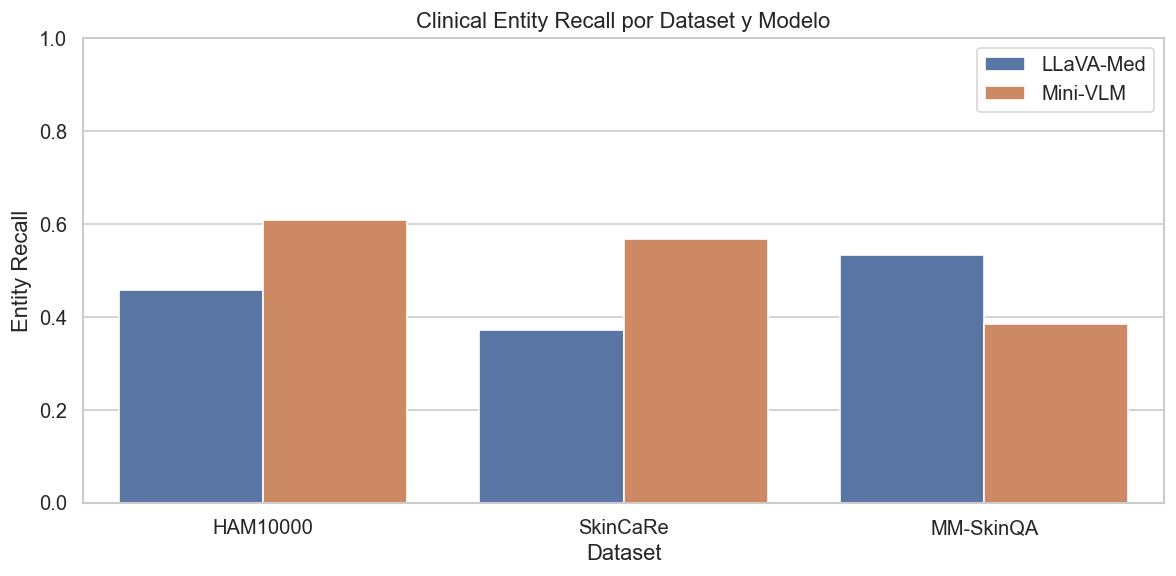

Dataset,HAM10000,MM-SkinQA,SkinCaRe
Modelo,,,
LLaVA-Med,0.4569,0.5333,0.3709
Mini-VLM,0.6068,0.3844,0.5661


In [11]:
# --- 4a. NER entity recall global ---
ner_all = {"HAM10000": ner_ham, "SkinCaRe": ner_skin, "MM-SkinQA": ner_mm}

ner_rows = []
for dataset_label, ner_dict in ner_all.items():
    for model, res in ner_dict.items():
        ner_rows.append({
            "Dataset": dataset_label,
            "Modelo": MODEL_LABELS[model],
            "Entity Recall": res["clinical_entity_recall"],
        })

if ner_rows:
    df_ner_global = pd.DataFrame(ner_rows)
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=df_ner_global, x="Dataset", y="Entity Recall", hue="Modelo", ax=ax)
    ax.set_title("Clinical Entity Recall por Dataset y Modelo")
    ax.set_ylim(0, 1.0)
    ax.legend()
    plt.tight_layout()
    plt.show()

    # Tabla pivot
    df_pivot = df_ner_global.pivot(index="Modelo", columns="Dataset", values="Entity Recall")
    display(df_pivot.map(lambda x: f"{x:.4f}" if pd.notna(x) else "-").style.set_caption("Tabla 7: Clinical Entity Recall global"))

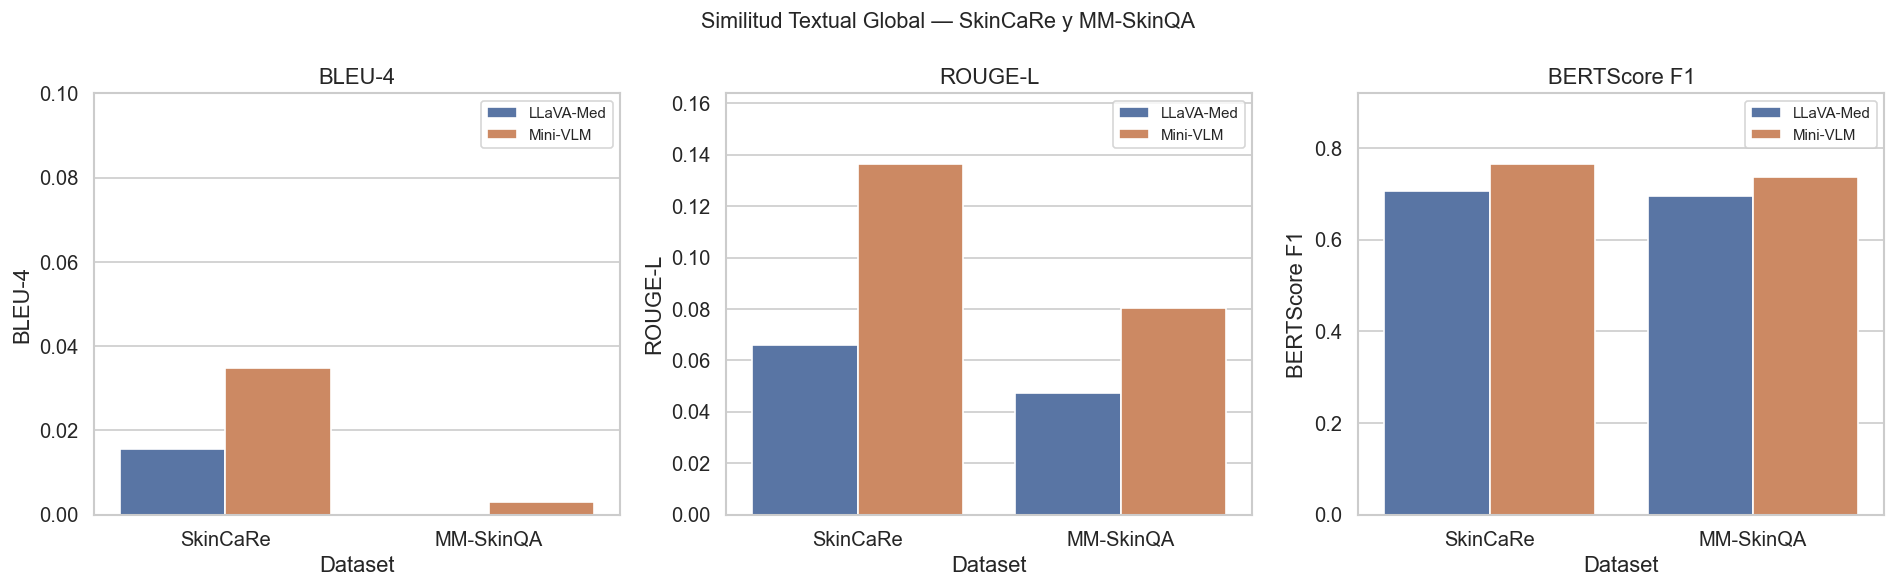

,Dataset,Modelo,BLEU-4,ROUGE-L,BERTScore F1
0,SkinCaRe,LLaVA-Med,0.0155,0.0660,0.7054
1,SkinCaRe,Mini-VLM,0.0347,0.1366,0.7663
2,MM-SkinQA,LLaVA-Med,0.0000,0.0473,0.6953
3,MM-SkinQA,Mini-VLM,0.0030,0.0803,0.7373


In [12]:
# --- 4b. Similitud textual global (SkinCaRe + MM-SkinQA) ---
gen_all = {"SkinCaRe": gen_skin, "MM-SkinQA": gen_mm}

gen_rows = []
for dataset_label, gen_dict in gen_all.items():
    for model, res in gen_dict.items():
        gen_rows.append({
            "Dataset": dataset_label,
            "Modelo": MODEL_LABELS[model],
            "BLEU-4": res.get("bleu_4"),
            "ROUGE-L": res.get("rouge_l"),
            "BERTScore F1": res.get("bertscore_f1"),
        })

if gen_rows:
    df_gen_global = pd.DataFrame(gen_rows)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    for ax, metric in zip(axes, ["BLEU-4", "ROUGE-L", "BERTScore F1"]):
        df_metric = df_gen_global[["Dataset", "Modelo", metric]].dropna()
        if df_metric.empty:
            ax.set_visible(False)
            continue
        sns.barplot(data=df_metric, x="Dataset", y=metric, hue="Modelo", ax=ax)
        ax.set_title(metric)
        ax.set_ylim(0, max(df_metric[metric].max() * 1.2, 0.1))
        ax.legend(fontsize=9)

    fig.suptitle("Similitud Textual Global — SkinCaRe y MM-SkinQA", fontsize=13)
    plt.tight_layout()
    plt.show()

    # Tabla resumen
    df_gen_display = df_gen_global.copy()
    for col in ["BLEU-4", "ROUGE-L", "BERTScore F1"]:
        df_gen_display[col] = df_gen_display[col].map(lambda x: f"{x:.4f}" if pd.notna(x) else "-")
    display(df_gen_display.style.set_caption("Tabla 8: Similitud textual global"))

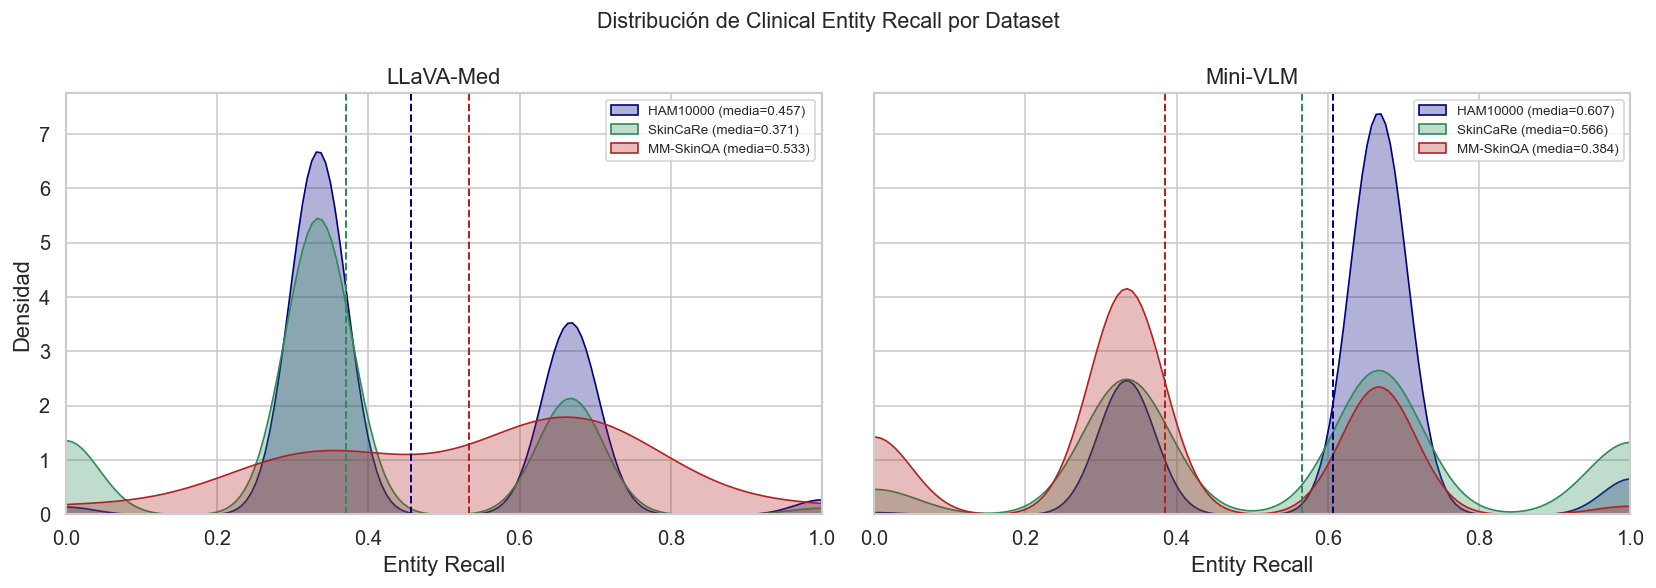

In [13]:
# --- 4c. Distribución de entity recall: comparación entre datasets ---
fig, axes = plt.subplots(1, len(MODELS), figsize=(14, 5), sharey=True)

dataset_colors = {"HAM10000": "navy", "SkinCaRe": "seagreen", "MM-SkinQA": "firebrick"}

for ax, model in zip(axes, MODELS):
    plotted = False
    for dataset_label, ner_dict in ner_all.items():
        res = ner_dict.get(model)
        if res is None:
            continue
        recalls = res["per_report_recall"]
        if not recalls:
            continue
        mean_r = res["clinical_entity_recall"]
        sns.kdeplot(
            recalls, fill=True, alpha=0.3,
            color=dataset_colors[dataset_label],
            label=f"{dataset_label} (media={mean_r:.3f})",
            ax=ax,
        )
        ax.axvline(mean_r, color=dataset_colors[dataset_label], linestyle="--", linewidth=1.2)
        plotted = True
    if plotted:
        ax.set_title(MODEL_LABELS[model])
        ax.set_xlabel("Entity Recall")
        ax.set_xlim(0, 1)
        ax.legend(fontsize=8)

axes[0].set_ylabel("Densidad")
fig.suptitle("Distribución de Clinical Entity Recall por Dataset", fontsize=13)
plt.tight_layout()
plt.show()

---
## 5. Observaciones

*(Completar manualmente tras ejecutar el notebook)*

**HAM10000:**
- Clasificación: ...
- NER entity recall: ...
- Diagnostic consistency: ...

**SkinCaRe:**
- NER entity recall: ...
- Similitud con resumen CoT (ROUGE-L / BERTScore): ...

**MM-SkinQA:**
- NER entity recall: ...
- Similitud con descripción histopatológica: ...

**Comparación global:**
- ...